# Water quality prediction: a guided walkthrough

Read the completed experiment without retraining. Run from this folder or the repository root, using the project virtual environment.

**Target:** the authors’ derived, row-level `CCME_Values`. The index is calculated from the same measurements as the model inputs; this is index emulation, not a drinking-water assessment.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
REPORTS = ROOT / 'reports'
manifest = json.loads((REPORTS / 'run_manifest.json').read_text())
manifest['config']

Out[0]: 
{'data': 'data/raw/combined/Combined_dataset.csv',
 'output': 'reports',
 'artifacts': 'artifacts',
 'seed': 42,
 'train_end': '2018-12-31',
 'validation_end': '2019-12-31',
 'calibration_end': '2020-12-31',
 'max_train_rows': 300000,
 'max_tuning_rows': 50000,
 'threads': 4,
 'xgb_estimators': 1000,
 'xgb_depths': [4, 6],
 'mlp_widths': [[64, 32], [128, 64]],
 'mlp_epochs': 60,
 'mlp_patience': 10,
 'batch_size': 2048,
 'alpha': 0.1,
 'explanation_rows': 2000}


## 1. Inspect the source audit

The formula audit reconstructs all released labels. A perfect reconstruction is evidence about target provenance, not model performance. See `docs/DATA.md` for the equation and the difference from official CCME WQI.

In [2]:
audit = json.loads((REPORTS / 'data_audit.json').read_text())
print('Rows:', f"{audit['raw_rows']:,}")
print('Duplicates removed:', audit['exact_duplicates_removed'])
print('Formula audit:', audit['formula_audit'])
pd.Series(audit['invalid_or_missing_by_feature'], name='Flagged readings')

Rows: 2,827,977
Duplicates removed: 9971
Formula audit: {'denominator': 12, 'mae': 1.2201434571066875e-15, 'max_absolute_error': 2.842170943040401e-14, 'fraction_matching_at_1e_7': 1.0, 'finite_reconstructions': 2827977}
Out[0]: 
Ammonia (mg/l)                         2
Biochemical Oxygen Demand (mg/l)       2
Dissolved Oxygen (mg/l)                0
Orthophosphate (mg/l)                 10
pH (ph units)                        505
Temperature (cel)                   5980
Nitrogen (mg/l)                        0
Nitrate (mg/l)                         0
Name: Flagged readings, dtype: int64


## 2. Check the evaluation design

Training ends in 2018. Validation, residual calibration and final evaluation use separate periods. A seeded 300,000-row training sample is shared by the models. A time holdout still permits historical sites to recur.

In [3]:
splits = json.loads((REPORTS / 'split_manifest.json').read_text())
pd.DataFrame({k: splits[k] for k in ['train', 'validation', 'calibration', 'test']}).T[['rows', 'start', 'end']]

Out[0]: 
                rows       start         end
train        2478761  1940-01-02  2018-12-28
validation     87177  2019-01-01  2019-12-31
calibration    49182  2020-01-01  2020-12-31
test          202886  2021-01-01  2023-12-17


## 3. Compare the measured results

MAE and RMSE are in index points; lower is better. R² compares against the test mean. Read interval coverage together with width, because wider intervals are easier to cover.

,family,architecture,mae,rmse,r2,seconds,best_step
0,XGBoost,4,0.138064,0.478137,0.998398,2.317499,999
1,XGBoost,6,0.119844,0.452701,0.998564,2.516983,803
2,MLP,"[64, 32]",0.641247,1.121080,0.991194,9.248160,59
3,MLP,"[128, 64]",0.469017,0.937145,0.993847,14.252856,60


,model,mae,rmse,r2,coverage,mean_width,radius,validation_rmse
0,Mean baseline,11.790940,13.458382,-0.414095,0.944767,31.745766,15.872883,13.461587
1,Ridge,4.344161,5.567582,0.757994,0.842315,13.956092,7.858564,5.567714
2,XGBoost,0.109925,0.426203,0.998582,0.884019,0.307336,0.197777,0.452033
3,MLP,0.446613,0.916082,0.993448,0.903424,2.259612,1.420632,0.937632
4,Blend,0.126738,0.422248,0.998608,0.893275,0.400176,0.253378,0.446864


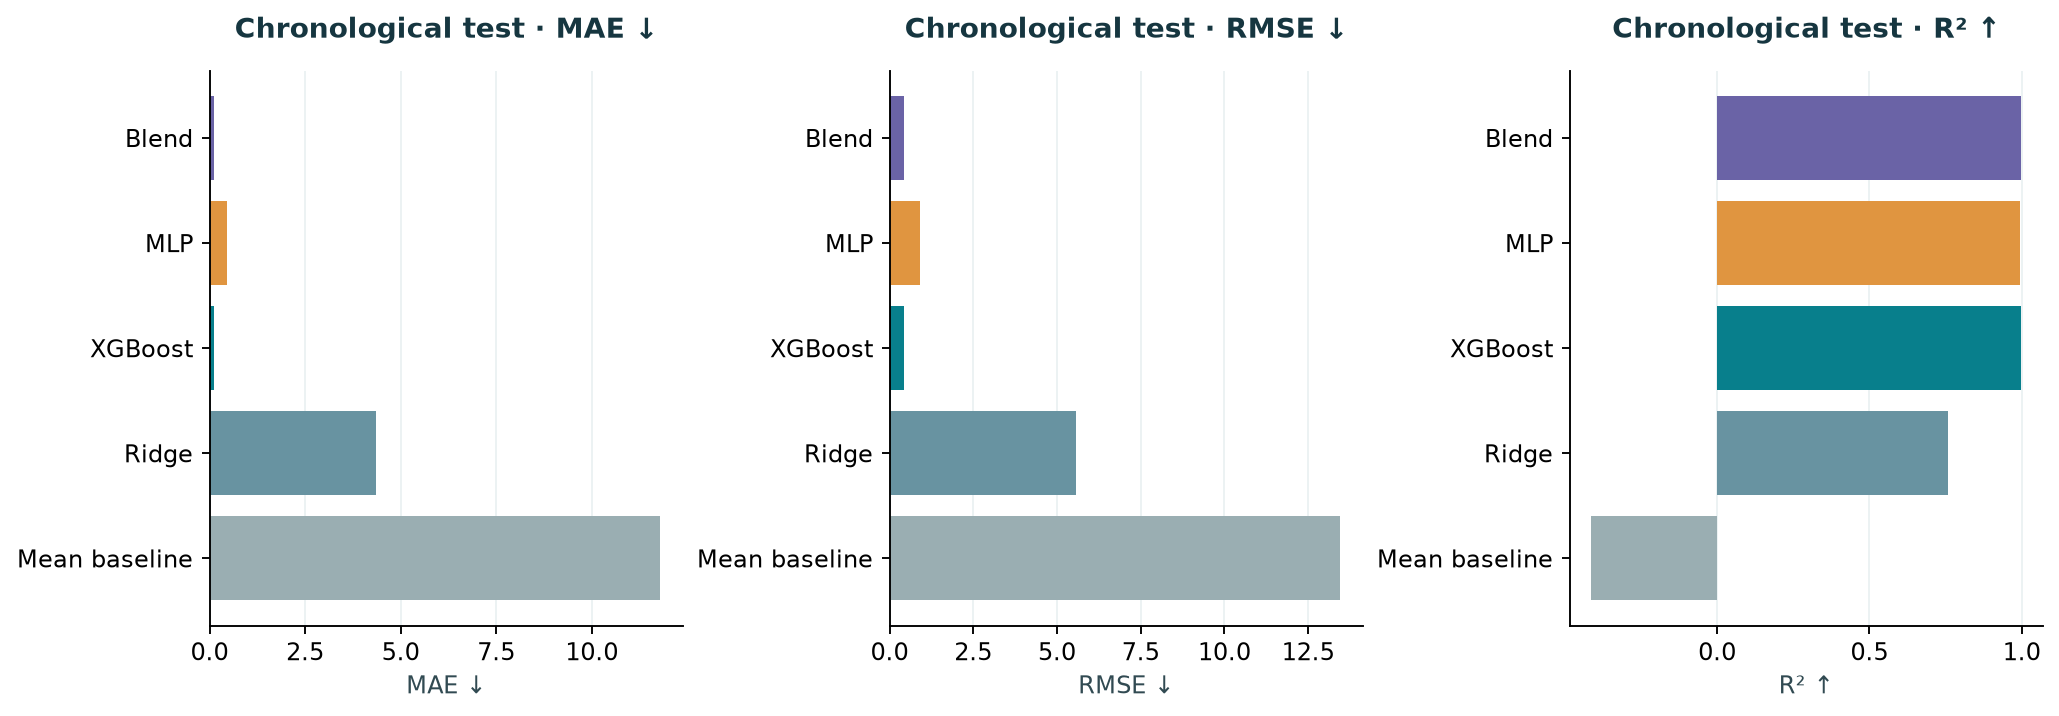

In [4]:
display(pd.read_csv(REPORTS / 'validation_candidates.csv'))
display(pd.read_csv(REPORTS / 'metrics.csv'))
display(Image(filename=str(REPORTS / 'figures/model_comparison.png')))

## 4. Look beyond aggregate scores

Country representation changes across time. Permutation importance measures reliance on shuffled validation inputs. SHAP attributes predictions; neither explains pollution causally.

,model,group_type,group,rows,mae,rmse,r2,coverage,mean_width,radius
0,Mean baseline,country,Canada,46,9.761095,12.580511,-0.029050,0.913043,31.745766,15.872883
1,Mean baseline,country,England,147199,10.711888,12.842381,-0.146398,0.924986,31.745766,15.872883
2,Mean baseline,country,Ireland,36230,14.678549,15.012951,-11.507647,0.996909,31.745766,15.872883
3,Mean baseline,country,USA,19411,14.588867,14.880531,-16.030504,0.997527,31.745766,15.872883
9,Ridge,country,Canada,46,6.435246,8.303212,0.551738,0.695652,14.061286,7.858564
10,Ridge,country,England,147199,4.680687,6.027748,0.747446,0.797329,14.900054,7.858564
11,Ridge,country,Ireland,36230,3.966264,4.586049,-0.167134,0.944300,12.262495,7.858564
12,Ridge,country,USA,19411,2.492572,3.007787,0.304200,0.993457,9.958561,7.858564
18,XGBoost,country,Canada,46,0.862104,1.774290,0.979531,0.521739,0.387816,0.197777
19,XGBoost,country,England,147199,0.136517,0.451222,0.998585,0.849225,0.335348,0.197777


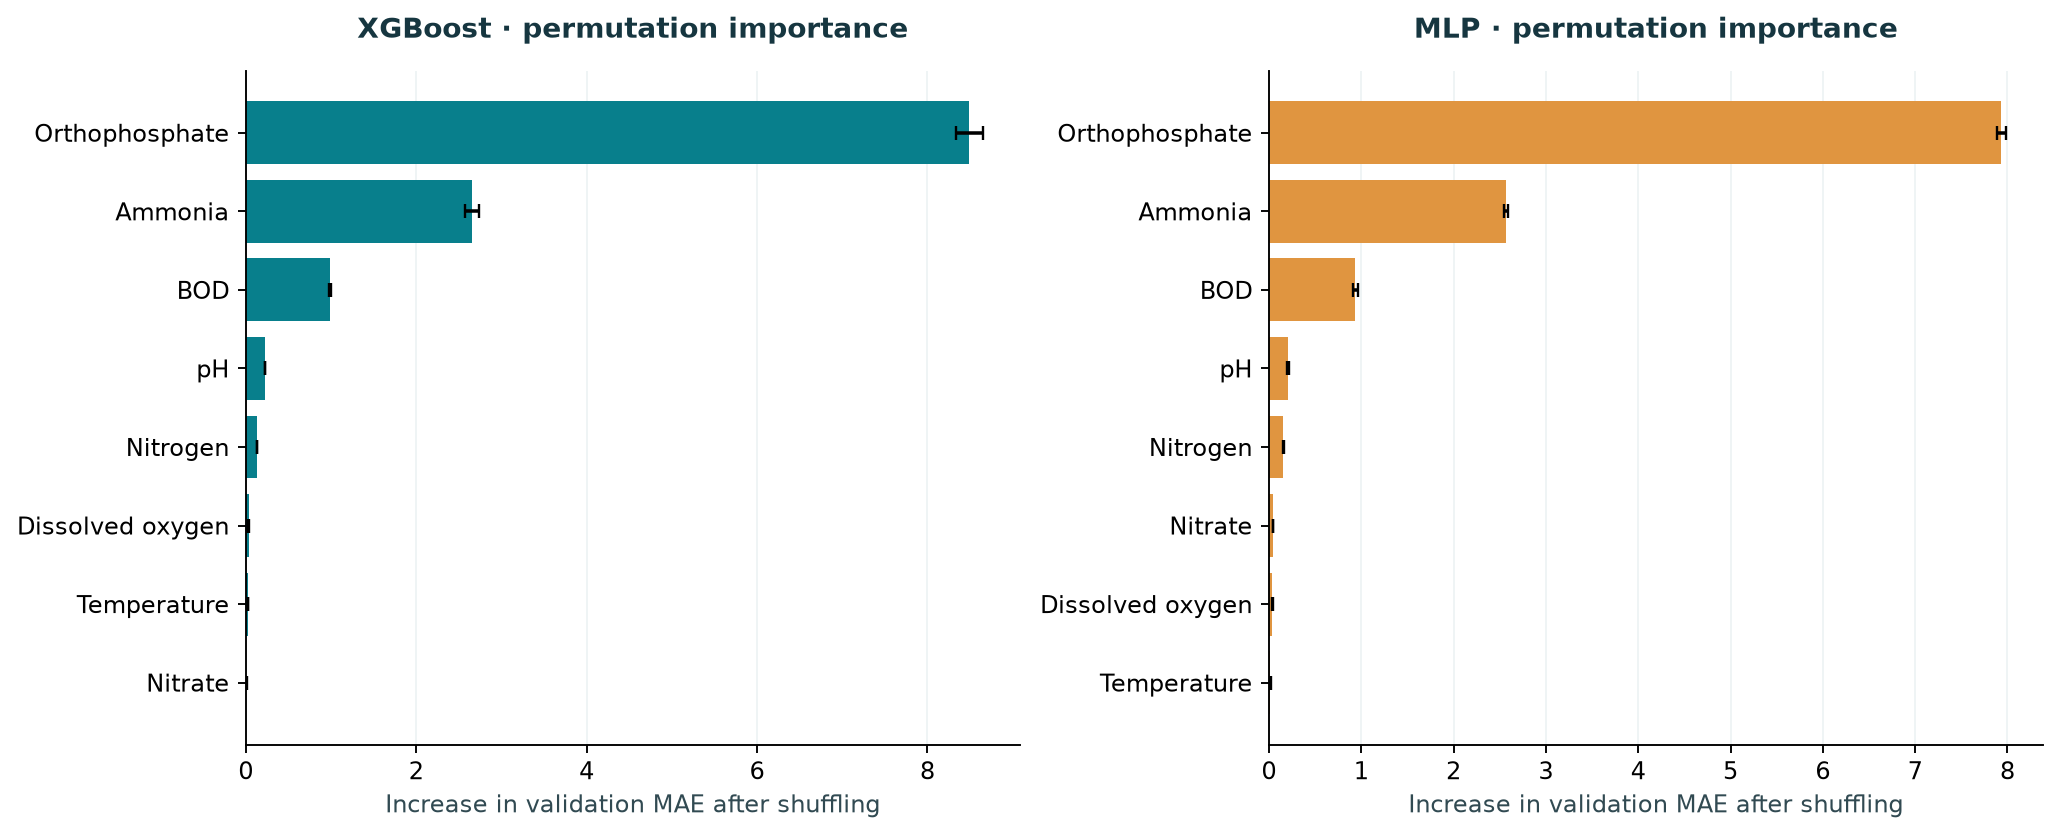

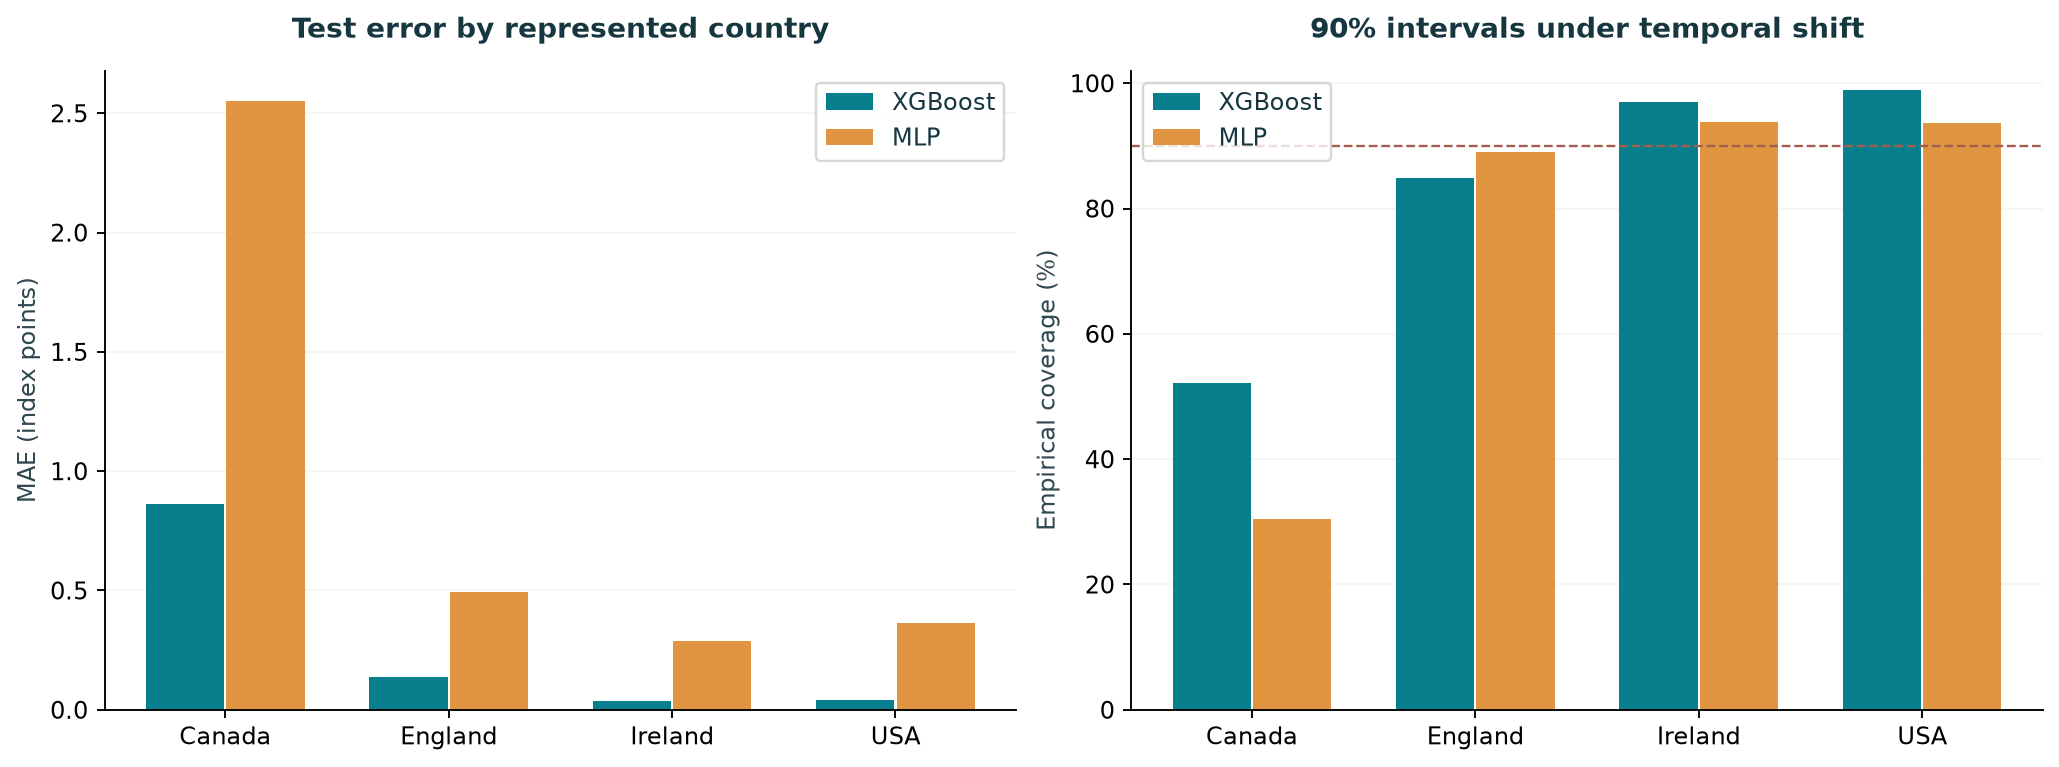

In [5]:
groups = pd.read_csv(REPORTS / 'subgroup_metrics.csv')
display(groups[groups.group_type == 'country'])
display(Image(filename=str(REPORTS / 'figures/feature_importance.png')))
display(Image(filename=str(REPORTS / 'figures/country_performance.png')))

## 5. Reload the saved model

No retraining occurs. Inputs must retain the provided column names and units. Missing/invalid input flags are returned with the result. Load only trusted project artifacts.

In [6]:
from water_quality.predict import predict_file
result = predict_file(ROOT / 'examples/measurements.csv', ROOT / 'artifacts', REPORTS / 'notebook_predictions.csv')
result[['predicted_source_index', 'lower_90', 'upper_90', 'model', 'input_review_required']]

Out[0]: 
   predicted_source_index   lower_90    upper_90  model  input_review_required
0               89.643517  89.390137   89.896896  Blend                  False
1               99.999260  99.745880  100.000000  Blend                  False
2               81.975815  81.722435   82.229195  Blend                  False
3               69.133331  68.879951   69.386711  Blend                  False
4               99.996658  99.743279  100.000000  Blend                  False


## Takeaway

When all formula inputs are available, compute this source index directly. To test real predictive value, collect independent outcomes, define a reduced sensor panel in advance, or predict a genuinely future target. Continue with `learning.md` for short theory notes and `reports/report.md` for the full findings.